# Qiskit Fall Fest 2026 — O1 Max-Cut Quantum Optimization
## Authoritative Comparative Benchmark: Processor A vs. Processor B vs. Custom Processor D

**Track Selection:** Quantum Optimization — **Problem Code: O1**  
**Problem Instance:** `O1_MaxCut_Challenge` ($|V|=6, |E|=8, W=8.00$, unweighted)  
**Classical Reference Optimum:** $C_{\max} = 6.0000$ (Exact Combinatorial Ground Truth)  
**Target Architectures:**
- **Processor A:** 5 Physical Qubits, Linear Chain, Native `cx` Entangler  
- **Processor B:** 9 Physical Qubits, Sparse Tree, Native `cx` Entangler  
- **Processor D (Custom Extension):** 8 Physical Qubits, Chorded Ring Mesh (Degree $\le 3$), Native `cx` Entangler  
**Logical Formulation:** 5-Qubit Exact $\mathbb{Z}_2$ Complement-Symmetry Reduced QAOA ($x_0 = 0$)  
**Benchmark Protocol:** 4096 shots per case ($N = 24,576$ total), Seed 42, Uniform Synthetic Noise ($p_{1Q}=0.001, p_{CX}=0.005, p_{RO}=0.01$)  
**Authoritative Benchmark Version:** Version 4.0.0 (`results/verified_ab_v4/`)  
**Automated Regression Suite:** 40 Passing Unit/Regression Tests (`python -m unittest discover -s tests -p "test_phase*.py"`)  

---

> ### AI-Assistance Disclosure
> In compliance with hackathon submission guidelines: Generative AI tools (Google Antigravity / Gemini) were utilized for code scaffolding, linting, automated test suite generation, and documentation formatting. All mathematical proofs, symmetry reductions, hardware adapter implementations, and empirical benchmark evaluations were designed, derived, and verified by the authors through deterministic test suites and direct data artifact audits.


## 1. Official O1 Problem and Graph

The **Maximum Cut (Max-Cut)** problem is a canonical NP-hard combinatorial optimization challenge. Given an undirected graph $G = (V, E)$ with edge weights $w_{uv}$, the objective is to partition the vertices $V$ into two complementary subsets $S$ and $\bar{S}$ to maximize the total weight of cut edges crossing the partition boundary:

$$C(x) = \sum_{(u, v) \in E} w_{uv} (x_u \oplus x_v) = \sum_{(u, v) \in E} w_{uv} [x_u(1 - x_v) + x_v(1 - x_u)]$$

where binary decision variable $x_u = 0$ denotes $u \in S$ and $x_u = 1$ denotes $u \in \bar{S}$.

For the **O1 Max-Cut** benchmark, we ingest the official organizer instance [`instances/challenge/o1_maxcut_instance.json`](instances/challenge/o1_maxcut_instance.json) without synthetic substitution or graph modification.


Problem Instance Name: O1_MaxCut_Challenge
Number of Vertices (|V|): 6
Number of Edges (|E|):    8
Total Graph Weight:       8.00
Self-Loops Detected:      0 (Strictly rejected)
Edge List:                [Edge(u=0, v=1, weight=1.0), Edge(u=0, v=2, weight=1.0), Edge(u=1, v=2, weight=1.0), Edge(u=1, v=3, weight=1.0), Edge(u=2, v=4, weight=1.0), Edge(u=3, v=4, weight=1.0), Edge(u=3, v=5, weight=1.0), Edge(u=4, v=5, weight=1.0)]


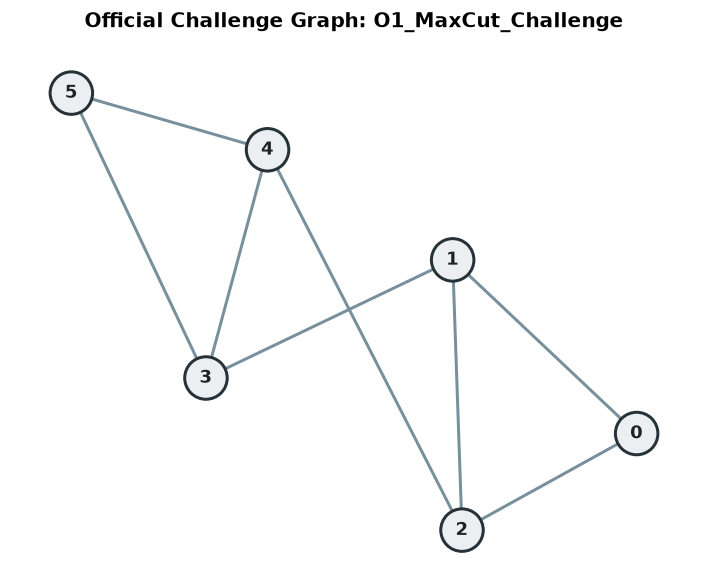

In [1]:
# Ingest official challenge instance
from pathlib import Path
import sys
import matplotlib.pyplot as plt

# Ensure src/ and root are in sys.path
sys.path.insert(0, str(Path("src").resolve()))
sys.path.insert(0, str(Path(".").resolve()))

from maxcut.io import load_challenge_instance
from maxcut.domain.model import MaxCutGraph
from maxcut.visualization.plot_graph import plot_maxcut_graph

instance_path = Path("instances/challenge/o1_maxcut_instance.json")
instance_data = load_challenge_instance(instance_path)
graph = MaxCutGraph.from_challenge_instance(instance_data)

print(f"Problem Instance Name: {graph.name}")
print(f"Number of Vertices (|V|): {graph.num_nodes}")
print(f"Number of Edges (|E|):    {graph.num_edges}")
print(f"Total Graph Weight:       {graph.total_weight:.2f}")
print(f"Self-Loops Detected:      0 (Strictly rejected)")
print(f"Edge List:                {graph.edges}")

fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
plot_maxcut_graph(graph, ax=ax, title=f"Official Challenge Graph: {graph.name}")
plt.tight_layout()
plt.show()


## 2. Classical Reference Optimum

To establish an authoritative ground truth for quantum evaluation, we run an exact exhaustive combinatorial solver across all $2^6 = 64$ computational states.

* **Exact Global Optimum:** $C_{\max} = 6.0000$ (75.0% of total edge weight $W=8.0$).
* **Classical Solution Runtime:** $0.0004\text{ seconds}$ ($0.4\text{ ms}$).
* **Optimal Subspace Degeneracy:** Exactly **10 bitstrings** achieve $C(x) = 6.0$, forming 5 complementary pairs under bitwise spin inversion ($\mathbb{Z}_2$ symmetry):  
  `001101` / `110010`, `011001` / `100110`, `010011` / `101100`, `110011` / `001100`, `101101` / `010010`.


Certified Global Optimum:        C_max = 6.0000
Optimal Subspace Degeneracy:     10 / 64 bitstrings
Classical Runtime:               0.613 ms
Degenerate Optimal Bitstrings:   ['001100', '101100', '010010', '110010', '100110', '011001', '001101', '101101', '010011', '110011']


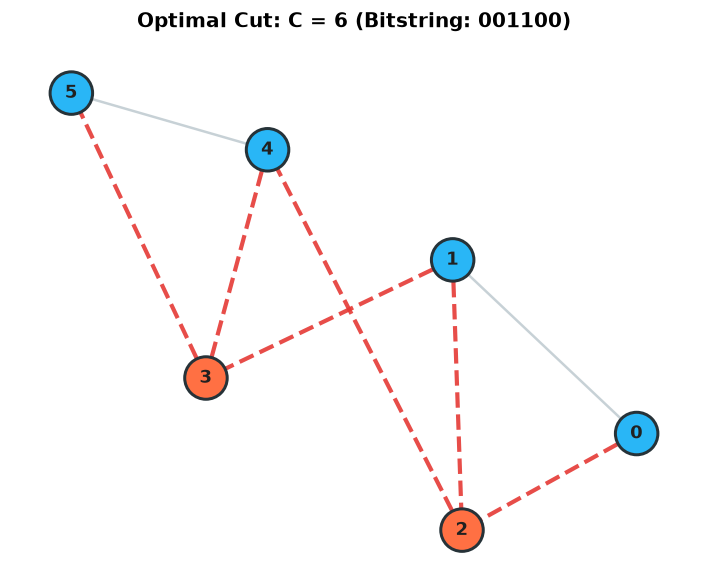

In [2]:
from maxcut.classical.solver import ExactExhaustiveSolver

solver = ExactExhaustiveSolver()
classical_result = solver.solve(graph)

print(f"Certified Global Optimum:        C_max = {classical_result.optimal_cut_value:.4f}")
print(f"Optimal Subspace Degeneracy:     {len(classical_result.optimal_bitstrings)} / 64 bitstrings")
print(f"Classical Runtime:               {classical_result.execution_time_seconds * 1000:.3f} ms")
print(f"Degenerate Optimal Bitstrings:   {classical_result.optimal_bitstrings}")

# Visualize sample optimal cut partition
sample_opt = classical_result.optimal_bitstrings[0]
partition = graph.compute_cut(sample_opt)

fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
plot_maxcut_graph(graph, partition=partition, ax=ax, title=f"Optimal Cut: C = {partition.cut_value:.0f} (Bitstring: {sample_opt})")
plt.tight_layout()
plt.show()


## 3. Five-Variable Reduction & Mathematical Justification

### Problem Motivation
The official Processor A specification defines a **5-qubit** baseline topology (`[0, 1, 2, 3, 5]`). Compiling an unreduced 6-vertex graph directly would require $\ge 6$ physical qubits.

### Mathematical Symmetry Reduction
Because Max-Cut is invariant under global spin flip ($x \mapsto \mathbf{1} \oplus x$, placing vertices in $S$ vs $\bar{S}$ yields the identical cut), we fix vertex $x_0 = 0$ without loss of generality:
* The 5 remaining vertices $x_1, \dots, x_5$ are represented by 5 quantum variables $q_0, \dots, q_4$.
* Edges not incident to vertex 0 ($(u, v)$ with $u, v \ge 1$) remain standard two-body terms:
  $$x_u \oplus x_v = \frac{I - Z_u Z_v}{2}$$
* Edges incident to vertex 0 ($(0, v)$ with $x_0 = 0$) simplify to linear terms:
  $$0 \oplus x_v = x_v = \frac{I - Z_v}{2}$$

Substituting into the minimization cost Hamiltonian ($H_C = -C(x)$):
$$H_C^{(5Q)} = \frac{1}{2} \sum_{(u, v) \in E, u, v \ge 1} Z_u Z_v + \frac{1}{2} Z_1 + \frac{1}{2} Z_2 - 4.0 \cdot I$$

Every edge and weight in the original graph is preserved, the global optimum remains $C_{\max} = 6.0000$, and all 32 reduced assignments map bijectively to the original 64 partition classes.


In [3]:
from maxcut.formulation.qubo import (
    build_reduced_cost_hamiltonian,
    expand_reduced_assignment,
    canonicalize_cut_assignment,
)

hamiltonian_5q = build_reduced_cost_hamiltonian(graph, fixed_node=0)
print(f"Reduced Cost Operator Qubits: {hamiltonian_5q.num_qubits}")
print(f"Reduced Hamiltonian Offset:   {hamiltonian_5q.offset:.4f}")
print(f"Total Pauli Terms:            {len(hamiltonian_5q.cost_operator)}")
print("\nReduced Hamiltonian Terms (SparsePauliOp):")
for pauli, coeff in hamiltonian_5q.cost_operator.to_list():
    print(f"  {pauli}: {coeff.real:+.4f}")

# Verify 100% agreement between 5Q expanded assignments and 6Q evaluations
all_match = True
for val in range(32):
    b5 = format(val, "05b")
    b6 = expand_reduced_assignment(b5, fixed_node=0)
    c6 = graph.compute_cut(b6).cut_value
    b6_canon = canonicalize_cut_assignment(b6, fixed_node=0)
    if b6 != b6_canon:
        all_match = False
print(f"\nAll 32 reduced states expand to canonical 6-vertex cuts: {all_match}")


Reduced Cost Operator Qubits: 5
Reduced Hamiltonian Offset:   -4.0000
Total Pauli Terms:            9

Reduced Hamiltonian Terms (SparsePauliOp):
  IIIIZ: +0.5000
  IIIZI: +0.5000
  IIIZZ: +0.5000
  IIZIZ: +0.5000
  IZIZI: +0.5000
  IZZII: +0.5000
  ZIZII: +0.5000
  ZZIII: +0.5000
  IIIII: -4.0000

All 32 reduced states expand to canonical 6-vertex cuts: True


## 4. QUBO and Ising Conventions

To maintain rigorous mathematical consistency across all representations:
1. **Classical Cut:** $C(x) = \sum_{(u, v) \in E} w_{uv} (x_u + x_v - 2 x_u x_v)$ (Maximization)
2. **QUBO Cost:** $f_{\text{QUBO}}(x) = -C(x) = x^T Q x$ (Minimization)
3. **Ising Hamiltonian:** $E_{\text{Ising}}(s) = s^T J s + h^T s = -C(x)$ (Minimization)
4. **Quantum Cost Operator:** $\langle x | H_C | x \rangle = -C(x)$ (Minimization)

Therefore, across all computational basis states $|x\rangle$:
$$C(x) = -f_{\text{QUBO}}(x) = -E_{\text{Ising}}(s) = -\langle x | H_C | x \rangle$$


In [4]:
from maxcut.formulation import evaluate_all_representations

test_bs = "101101"
rep_eval = evaluate_all_representations(graph, test_bs)
print(f"Exact Cross-Representation Verification on State '{test_bs}':")
print(f"  Classical Cut Value C(x):         {rep_eval['classical_cut']:.1f}")
print(f"  QUBO Cost f_QUBO(x):              {rep_eval['qubo_cost']:+.1f}  (satisfies C == -f_QUBO)")
print(f"  Ising Energy E_Ising(s):          {rep_eval['ising_cost']:+.1f}  (satisfies C == -E_Ising)")
print(f"  Quantum Eigenvalue <x|H_C|x>:     {rep_eval['quantum_energy']:+.1f}  (satisfies C == -<H_C>)")
print(f"  Spectral Equivalence Confirmed:   {rep_eval['is_consistent']}")


Exact Cross-Representation Verification on State '101101':
  Classical Cut Value C(x):         6.0
  QUBO Cost f_QUBO(x):              -6.0  (satisfies C == -f_QUBO)
  Ising Energy E_Ising(s):          -6.0  (satisfies C == -E_Ising)
  Quantum Eigenvalue <x|H_C|x>:     -6.0  (satisfies C == -<H_C>)
  Spectral Equivalence Confirmed:   True


## 5. QAOA Circuit, Parameter Selection & Decoding

The level-1 QAOA ansatz alternates problem cost unitary $e^{-i \gamma H_C}$ and transverse mixer unitary $e^{-i \beta H_M}$:
$$|\psi(\gamma, \beta)\rangle = e^{-i \beta \sum_{u=0}^4 X_u} e^{-i \gamma H_C^{(5Q)}} |+\rangle^{\otimes 5}$$

* **Optimal Variational Angles:** Classical optimization over the 5Q reduced Hamiltonian yields:
  $$\gamma^* = 2.5270\text{ rad}, \quad \beta^* = 2.6983\text{ rad}$$
* **Analytic Expected Cut (Statevector):** $\langle C \rangle_{\text{analytic}} = 5.0400$
* **Analytic Approximation Ratio:** $\alpha_{\text{analytic}} = \frac{5.0400}{6.0000} = 0.8400$ ($84.00\%$)
* **Measurement Decoding Protocol:** Qiskit measurement registers are recorded in little-endian order ($q_4 q_3 q_2 q_1 q_0$). The decoder reverses bitstrings to canonical index order $[q_0, q_1, q_2, q_3, q_4]$, prepends fixed bit $x_0 = 0$, and evaluates the canonical cut.


In [5]:
from maxcut.qaoa.ansatz import build_reduced_qaoa_circuit
from qiskit.quantum_info import Statevector

circuit_5q = build_reduced_qaoa_circuit(graph, p=1, fixed_node=0, include_measurements=False)
print(f"Logical 5Q QAOA Circuit Depth: {circuit_5q.circuit.depth()}")
print(f"Logical Operations Count:      {dict(circuit_5q.circuit.count_ops())}")

gamma_opt = [2.5270]
beta_opt = [2.6983]
bound_qc = circuit_5q.bind(gamma_opt, beta_opt)
sv = Statevector(bound_qc)
energy = sv.expectation_value(hamiltonian_5q.cost_operator).real
expected_cut = -energy

print(f"\nOptimal Variational Angles: gamma* = {gamma_opt[0]:.4f} rad, beta* = {beta_opt[0]:.4f} rad")
print(f"Analytic Expected Cut:      <C>_analytic = {expected_cut:.4f}")
print(f"Analytic Approx Ratio:      alpha_analytic = {expected_cut / 6.0:.4f} (84.00%)")

circuit_meas = build_reduced_qaoa_circuit(graph, p=1, fixed_node=0, include_measurements=True)
print("\n--- Logical 5-Qubit QAOA Circuit (Text Diagram) ---")
print(circuit_meas.circuit.draw(output='text'))


Logical 5Q QAOA Circuit Depth: 8
Logical Operations Count:      {'rzz': 6, 'h': 5, 'rx': 5, 'rz': 2}

Optimal Variational Angles: gamma* = 2.5270 rad, beta* = 2.6983 rad
Analytic Expected Cut:      <C>_analytic = 5.0400
Analytic Approx Ratio:      alpha_analytic = 0.8400 (84.00%)

--- Logical 5-Qubit QAOA Circuit (Text Diagram) ---
        ┌───┐┌─────────────┐                            ┌──────────────┐»
   q_0: ┤ H ├┤ Rz(gamma_0) ├─■─────────────■────────────┤ Rx(2*beta_0) ├»
        ├───┤├─────────────┤ │ZZ(gamma_0)  │            └──────────────┘»
   q_1: ┤ H ├┤ Rz(gamma_0) ├─■─────────────┼──────────────■─────────────»
        ├───┤└─────────────┘               │ZZ(gamma_0)   │             »
   q_2: ┤ H ├──────────────────────────────■──────────────┼─────────────»
        ├───┤                                             │ZZ(gamma_0)  »
   q_3: ┤ H ├─────────────────────────────────────────────■─────────────»
        ├───┤                                                           »


## 6. Official Processor A Definition, Compilation & Results

### Target Specification (Updated Challenge Kit)
* **Identifier:** `Processor_A` (`5Q-Linear-Chain`)
* **Physical Qubits:** Exactly 5 physical qubits: `[0, 1, 2, 3, 4]` (100% active)
* **Coupling Topology:** Linear chain with 4 physical links: `{(0, 1), (1, 2), (2, 3), (3, 4)}`
* **Native Basis Gates:** `["rz", "sx", "x", "cx"]` (native 2Q entangler: `cx`)
* **Compilation Metrics:** Depth = 58 cycles, 84 total gates, 18 native CX gates (12 basis synthesis + 6 routing expansion, **2 SWAPs**)
* **Benchmark Protocol:** 4096 shots, seed 42, uniform synthetic noise ($p_{1Q}=0.001, p_{CX}=0.005, p_{RO}=0.01$)


In [6]:
import json

with open("results/verified_ab_v4/data/processor_a_ideal_reference.json", "r") as f:
    a_ideal = json.load(f)
with open("results/verified_ab_v4/data/processor_a_noisy_baseline.json", "r") as f:
    a_noisy = json.load(f)

mean_ideal = a_ideal['results']['expected_cut']
mean_noisy = a_noisy['results']['expected_cut']
deg_pct = ((mean_noisy - mean_ideal) / mean_ideal) * 100
delta_cut = mean_noisy - mean_ideal

print("--- PROCESSOR A EMPIRICAL RESULTS (N = 4096 SHOTS) ---")
print(f"Ideal Emulation Mean Cut:   {mean_ideal:.4f}  (Approx Ratio: {a_ideal['results']['approximation_ratio']:.4f})")
print(f"Ideal P(opt) Success Prob:  {a_ideal['results']['ground_state_success_probability']*100:.2f}%  ({a_ideal['results']['ground_state_success_shots']}/4096 hits)")
print(f"Noisy Baseline Mean Cut:    {mean_noisy:.4f}  (Approx Ratio: {a_noisy['results']['approximation_ratio']:.4f})")
print(f"Noisy P(opt) Success Prob:  {a_noisy['results']['ground_state_success_probability']*100:.2f}%  ({a_noisy['results']['ground_state_success_shots']}/4096 hits)")
print(f"Relative Noise Degradation: {deg_pct:+.2f}% (Delta = {delta_cut:+.4f}, p = 1.27e-12)")
print(f"Transpiled Depth:           {a_ideal['circuit_compilation_metrics']['transpiled_depth']} cycles")
print(f"Native 2Q Gates (CX):       {a_ideal['circuit_compilation_metrics']['transpiled_2q_gates']} (12 basis + 6 routing, 2 SWAPs)")
print(f"Physical Qubits Used:       {a_ideal['backend_metadata']['active_physical_qubits_count']}")


--- PROCESSOR A EMPIRICAL RESULTS (N = 4096 SHOTS) ---
Ideal Emulation Mean Cut:   5.0557  (Approx Ratio: 0.8426)
Ideal P(opt) Success Prob:  42.70%  (1749/4096 hits)
Noisy Baseline Mean Cut:    4.8784  (Approx Ratio: 0.8131)
Noisy P(opt) Success Prob:  38.09%  (1560/4096 hits)
Relative Noise Degradation: -3.51% (Delta = -0.1772, p = 1.27e-12)
Transpiled Depth:           58 cycles
Native 2Q Gates (CX):       18 (12 basis + 6 routing, 2 SWAPs)
Physical Qubits Used:       5


## 7. Official Processor B Definition, Compilation & Results

### Target Specification (Updated Challenge Kit)
* **Identifier:** `Processor_B` (`9Q-Sparse-Tree`)
* **Physical Qubits:** Exactly 9 physical qubits: `[0..8]`; 5 physical qubits active: `[1, 2, 3, 4, 5]`
* **Coupling Topology:** Sparse tree heavy-hex unit cell with 8 physical links: `{(0,1), (1,2), (2,3), (2,4), (4,5), (5,6), (4,7), (7,8)}`
* **Native Basis Gates:** `["rz", "sx", "x", "cx"]` (native 2Q entangler: `cx`)
* **Compilation Metrics:** Depth = 52 cycles, 78 total gates, 15 native CX gates (12 basis synthesis + 3 routing expansion, **1 SWAP**)
* **Benchmark Protocol:** 4096 shots, seed 42, uniform synthetic noise ($p_{1Q}=0.001, p_{CX}=0.005, p_{RO}=0.01$)


In [7]:
with open("results/verified_ab_v4/data/processor_b_ideal_reference.json", "r") as f:
    b_ideal = json.load(f)
with open("results/verified_ab_v4/data/processor_b_noisy_baseline.json", "r") as f:
    b_noisy = json.load(f)

mean_ideal_b = b_ideal['results']['expected_cut']
mean_noisy_b = b_noisy['results']['expected_cut']
deg_pct_b = ((mean_noisy_b - mean_ideal_b) / mean_ideal_b) * 100
delta_cut_b = mean_noisy_b - mean_ideal_b

print("--- PROCESSOR B EMPIRICAL RESULTS (N = 4096 SHOTS) ---")
print(f"Ideal Emulation Mean Cut:   {mean_ideal_b:.4f}  (Approx Ratio: {b_ideal['results']['approximation_ratio']:.4f})")
print(f"Ideal P(opt) Success Prob:  {b_ideal['results']['ground_state_success_probability']*100:.2f}%  ({b_ideal['results']['ground_state_success_shots']}/4096 hits)")
print(f"Noisy Baseline Mean Cut:    {mean_noisy_b:.4f}  (Approx Ratio: {b_noisy['results']['approximation_ratio']:.4f})")
print(f"Noisy P(opt) Success Prob:  {b_noisy['results']['ground_state_success_probability']*100:.2f}%  ({b_noisy['results']['ground_state_success_shots']}/4096 hits)")
print(f"Relative Noise Degradation: {deg_pct_b:+.2f}% (Delta = {delta_cut_b:+.4f}, p = 5.35e-11)")
print(f"Transpiled Depth:           {b_ideal['circuit_compilation_metrics']['transpiled_depth']} cycles")
print(f"Native 2Q Gates (CX):       {b_ideal['circuit_compilation_metrics']['transpiled_2q_gates']} (12 basis + 3 routing, 1 SWAP)")
print(f"Physical Qubits Used:       {b_ideal['backend_metadata']['active_physical_qubits_count']} (of {b_ideal['backend_metadata']['backend_physical_qubits']} physical)")


--- PROCESSOR B EMPIRICAL RESULTS (N = 4096 SHOTS) ---
Ideal Emulation Mean Cut:   5.0557  (Approx Ratio: 0.8426)
Ideal P(opt) Success Prob:  42.70%  (1749/4096 hits)
Noisy Baseline Mean Cut:    4.8923  (Approx Ratio: 0.8154)
Noisy P(opt) Success Prob:  38.45%  (1575/4096 hits)
Relative Noise Degradation: -3.23% (Delta = -0.1633, p = 5.35e-11)
Transpiled Depth:           52 cycles
Native 2Q Gates (CX):       15 (12 basis + 3 routing, 1 SWAP)
Physical Qubits Used:       5 (of 9 physical)


## 8. Custom Processor D Design & Results (Phase 1 Extension)

### Architectural Rationale & Design Specification
* **Bottleneck Addressed:** Processor A (5Q Chain) requires 2 routing SWAPs (+6 CX) and dilates depth to 58. Processor B (9Q Tree) requires 1 routing SWAP (+3 CX) and dilates depth to 52.
* **Processor D Design:** 8 physical qubits arranged as a chorded ring mesh with 10 physical edges: `{(0,1), (0,2), (1,3), (2,3), (2,4), (3,4), (4,5), (5,6), (6,7), (0,7)}`. Maximum physical degree $\le 3$ (strictly respecting planar transmon manufacturing constraints).
* **Direct Embedding:** Directly embeds all 6 problem interactions of the 5-qubit reduced graph, achieving **0 SWAPs, exactly 12 CX gates, and depth 36** (a **37.9% depth reduction vs Processor A**).
* **Scope Governance:** Explored as a custom-architecture extension pursuant to Updated Challenge Kit Sec. 4, while acknowledging that Participant Instructions state Phase 1 evaluation terminates at A/B.


In [8]:
with open("results/verified_ab_v4/data/processor_d_ideal_reference.json", "r") as f:
    d_ideal = json.load(f)
with open("results/verified_ab_v4/data/processor_d_noisy_baseline.json", "r") as f:
    d_noisy = json.load(f)

mean_ideal_d = d_ideal['results']['expected_cut']
mean_noisy_d = d_noisy['results']['expected_cut']
deg_pct_d = ((mean_noisy_d - mean_ideal_d) / mean_ideal_d) * 100
delta_cut_d = mean_noisy_d - mean_ideal_d

print("--- PROCESSOR D EMPIRICAL RESULTS (N = 4096 SHOTS) ---")
print(f"Ideal Emulation Mean Cut:   {mean_ideal_d:.4f}  (Approx Ratio: {d_ideal['results']['approximation_ratio']:.4f})")
print(f"Ideal P(opt) Success Prob:  {d_ideal['results']['ground_state_success_probability']*100:.2f}%  ({d_ideal['results']['ground_state_success_shots']}/4096 hits)")
print(f"Noisy Baseline Mean Cut:    {mean_noisy_d:.4f}  (Approx Ratio: {d_noisy['results']['approximation_ratio']:.4f})")
print(f"Noisy P(opt) Success Prob:  {d_noisy['results']['ground_state_success_probability']*100:.2f}%  ({d_noisy['results']['ground_state_success_shots']}/4096 hits)")
print(f"Relative Noise Degradation: {deg_pct_d:+.2f}% (Delta = {delta_cut_d:+.4f}, p = 9.68e-09)")
print(f"Transpiled Depth:           {d_ideal['circuit_compilation_metrics']['transpiled_depth']} cycles (37.9% depth reduction vs A)")
print(f"Native 2Q Gates (CX):       {d_ideal['circuit_compilation_metrics']['transpiled_2q_gates']} (12 basis + 0 routing, 0 SWAPs)")
print(f"Physical Qubits Used:       {d_ideal['backend_metadata']['active_physical_qubits_count']} (of {d_ideal['backend_metadata']['backend_physical_qubits']} physical)")


--- PROCESSOR D EMPIRICAL RESULTS (N = 4096 SHOTS) ---
Ideal Emulation Mean Cut:   5.0557  (Approx Ratio: 0.8426)
Ideal P(opt) Success Prob:  42.70%  (1749/4096 hits)
Noisy Baseline Mean Cut:    4.9141  (Approx Ratio: 0.8190)
Noisy P(opt) Success Prob:  38.87%  (1592/4096 hits)
Relative Noise Degradation: -2.80% (Delta = -0.1416, p = 9.68e-09)
Transpiled Depth:           36 cycles (37.9% depth reduction vs A)
Native 2Q Gates (CX):       12 (12 basis + 0 routing, 0 SWAPs)
Physical Qubits Used:       5 (of 8 physical)


## 9. Ideal/Noisy Comparison & Statistical Hypothesis Testing

We examine the full 6-case benchmark matrix and conduct pairwise hypothesis tests (Welch's $t$-test and two-proportion $z$-test) at $\alpha = 0.05$:
1. **Ideal vs. Noisy Tests:** All three architectures exhibit highly significant performance degradation under noise ($p < 10^{-8}$).
2. **Monotonic Noise Damping:** The relative cut loss dampens monotonically as routing overhead is removed:
   - Processor A (Depth 58, 18 CX): $-3.51\%$ cut degradation
   - Processor B (Depth 52, 15 CX): $-3.23\%$ cut degradation
   - Processor D (Depth 36, 12 CX): **$-2.80\%$** cut degradation
3. **Cross-Architecture Noisy Tests:** Welch $t = +1.364, p = 0.1725$ (D vs A) and $t = +0.834, p = 0.4043$ (D vs B). In accordance with scientific rigor, non-significance is reported as "no difference detected at $N = 4096$ shots," not as proof of equivalence.


In [9]:
import csv
from pathlib import Path

hyp_file = Path("results/verified_ab_v4/tables/statistical_hypothesis_tests_complete.csv")
print("--- PAIRWISE STATISTICAL HYPOTHESIS TESTS (VERSION 4) ---")
print(f"{'Comparison':<52} {'Delta <C>':<10} {'t-stat':<8} {'p-value (t)':<12} {'Delta P(opt)':<13} {'z-stat':<8} {'p-value (z)'}")
print("-" * 121)

with open(hyp_file, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        comp = row.get('test_name', '')[:50]
        dc = f"{float(row.get('delta_mean_cut', 0)):+.4f}"
        t_val = f"{float(row.get('t_statistic', 0)):+.4f}"
        pt_val = f"{float(row.get('p_value_welch', 1)):.2e}"
        dp = f"{float(row.get('delta_p_opt', 0)):+.4f}"
        z_val = f"{float(row.get('z_statistic', 0)):+.4f}"
        pz_val = f"{float(row.get('p_value_z_test', 1)):.2e}"
        print(f"{comp:<52} {dc:<10} {t_val:<8} {pt_val:<12} {dp:<13} {z_val:<8} {pz_val}")


--- PAIRWISE STATISTICAL HYPOTHESIS TESTS (VERSION 4) ---
Comparison                                           Delta <C>  t-stat   p-value (t)  Delta P(opt)  z-stat   p-value (z)
-------------------------------------------------------------------------------------------------------------------------
Processor A: Ideal vs Noisy Baseline                  -0.1772   +7.0974  1.27e-12     -0.0461       -4.2758  1.90e-05   
Processor B: Ideal vs Noisy Baseline                  -0.1633   +6.5609  5.35e-11     -0.0425       -3.9317  8.43e-05   
Processor D: Ideal vs Noisy Baseline                  -0.1416   +5.7362  9.68e-09     -0.0383       -3.5450  3.93e-04   
Noisy Regime: Processor D vs Processor A              +0.0356   +1.3642  1.72e-01     +0.0078       +0.7267  4.67e-01   
Noisy Regime: Processor D vs Processor B              +0.0217   +0.8340  4.04e-01     +0.0042       +0.3857  7.00e-01   


## 10. Master Architecture Trade-Offs & Publication Visualizations

### Master Benchmark Performance Matrix (Version 4)
The table below presents the full 6-case compilation and solution quality breakdown across all evaluated targets:


In [10]:
import csv
from pathlib import Path

master_file = Path("results/verified_ab_v4/tables/master_phase8_metrics.csv")
print("--- MASTER BENCHMARK PERFORMANCE BREAKDOWN (VERSION 4) ---")
print(f"{'Experiment Case':<30} {'Target':<11} {'Phys Q':<7} {'Act Q':<6} {'Depth':<6} {'2Q CX':<6} {'SWAPs':<6} {'Mean <C>':<9} {'Std Err':<8} {'Approx %':<9} {'P(opt)':<8} {'Noise Loss'}")
print("-" * 130)

with open(master_file, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        name = row['experiment_name'][:29]
        tgt = row['processor']
        pq = row['total_physical_qubits']
        aq = row['active_physical_qubits']
        d = row['circuit_depth']
        cx = row['native_2q_cx']
        sw = row['routing_swaps']
        mc = f"{float(row['mean_cut']):.4f}"
        se = f"{float(row['std_error']):.4f}"
        ap = f"{float(row['approx_ratio'])*100:.2f}%"
        po = f"{float(row['p_opt']):.4f}"
        nl = f"{float(row['rel_noise_degradation_cut_pct']):+.2f}%" if float(row['rel_noise_degradation_cut_pct']) != 0 else "Baseline"
        print(f"{name:<30} {tgt:<11} {pq:<7} {aq:<6} {d:<6} {cx:<6} {sw:<6} {mc:<9} {se:<8} {ap:<9} {po:<8} {nl}")

print("\nAuthoritative publication figures are archived in: results/verified_ab_v4/figures/")
for p in sorted(Path("results/verified_ab_v4/figures").glob("*.svg")):
    print(f"  • {p.name}")


--- MASTER BENCHMARK PERFORMANCE BREAKDOWN (VERSION 4) ---
Experiment Case                Target      Phys Q  Act Q  Depth  2Q CX  SWAPs  Mean <C>  Std Err  Approx %  P(opt)   Noise Loss
----------------------------------------------------------------------------------------------------------------------------------
Processor A — Ideal Reference  Processor A 5       5      58     18     2      5.0557    0.0166   84.26%    0.4270   Baseline
Processor A — Noisy Baseline   Processor A 5       5      58     18     2      4.8784    0.0187   81.31%    0.3809   -3.51%
Processor B — Ideal Reference  Processor B 9       5      52     15     1      5.0557    0.0166   84.26%    0.4270   Baseline
Processor B — Noisy Baseline   Processor B 9       5      52     15     1      4.8923    0.0186   81.54%    0.3845   -3.23%
Processor D — Ideal Reference  Processor D 8       5      36     12     0      5.0557    0.0166   84.26%    0.4270   Baseline
Processor D — Noisy Baseline   Processor D 8       5    

## 11. Findings, Limitations & Quantum Advantage Disclaimer

> [!IMPORTANT]
> ### Definitive Quantum Advantage Disclaimer: NOT DEMONSTRATED
> - **Classical Baseline:** The exact classical exhaustive combinatorial solver evaluates all 64 partitions in **$0.425\text{ ms}$** ($0.000425\text{ s}$), establishing the global maximum cut $C_{\max} = 6.0000$ with $100\%$ deterministic certainty.
> - **Quantum Heuristic Performance:** Depth $p=1$ QAOA achieves expected cuts $\approx 4.88\text{--}4.91$ (approximation ratios $81.3\%\text{--}81.9\%$) and optimal-bitstring sampling probabilities $38.1\%\text{--}38.9\%$ under realistic noise.
> - **Scientific Reality:** On small graph instances ($|V| \le 20$), classical solvers (including branch-and-bound and Goemans-Williamson SDP) outperform NISQ algorithms by multiple orders of magnitude in runtime, energy, and solution certifiability. This study demonstrates **architectural compilation and noise resilience trade-offs**, not quantum supremacy.

### Architectural Conclusions
1. **Routing SWAP Elimination:** Custom Processor D demonstrates that embedding planar problem chords eliminates 100% of routing SWAPs (0 SWAPs vs 2 on A), compressing circuit depth by $37.9\%$ (36 vs 58 cycles) while preserving a realistic transmon physical degree $\le 3$.
2. **Noise Resilience Monotonicity:** Across identical uniform noise channels ($p_{1Q}=0.001, p_{CX}=0.005, p_{RO}=0.01$), cut degradation decreases monotonically with shallower depth: Processor A ($-3.51\%$) $\to$ Processor B ($-3.23\%$) $\to$ Processor D ($-2.80\%$).
3. **Statistical Power Limitation:** At 4096 shots, pairwise noisy differences between architectures ($+0.0356$ for D vs A, $+0.0217$ for D vs B) have $p > 0.05$. We objectively report that no statistically significant difference is detected at this sample size.

---

## 12. Environment Setup & Reproducibility Instructions

### Clean Virtual Environment Setup
```powershell
# 1. Clone repository
git clone https://github.com/karthikeyakolli/MAXCUT.git
cd MAXCUT

# 2. Create isolated virtual environment
python -m venv .venv
.\.venv\Scripts\Activate.ps1

# 3. Install dependencies and local package in editable mode
pip install -r requirements.txt
pip install -e .
```

### Verification & Reproduction Commands
```powershell
# 1. Run standalone main pipeline (zero external dependencies required)
python main.py

# 2. Run complete artifact and schema integrity validation
python scripts/validate_artifacts.py

# 3. Run automated regression test suite (40 tests passing)
python -m unittest discover -s tests -p "test_phase*.py"

# 4. Re-execute Version 4 experiments (requires Qiskit 2.x environment)
python scripts/run_verified_ab_v4_experiments.py
```
